# CSI-based 5G UE localization: CNN vs Vision Transformer
DeepMIMO O1 3.5 GHz, BS t006, 30k users, CSI = 32 antennas x 32 subcarriers.

**Colab:** Runtime > Change runtime type > GPU (T4). Upload `csi_o1.mat` to Google Drive and set `DATA_PATH`.

## 1. Setup

In [ ]:
import os, time, json
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from scipy.io import loadmat

import sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_PATH = '/content/drive/MyDrive/csi_o1.mat'   # <- adjust
else:
    DATA_PATH = 'csi_o1.mat'

FIG_DIR = 'figs'; os.makedirs(FIG_DIR, exist_ok=True)
SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

# Experiment settings
BLOCK_M     = 10      # spatial split block size along the street (m)
EPOCHS_CNN  = 40
EPOCHS_VIT  = 60
BATCH       = 256
FAST        = False   # True = few epochs, for a quick end-to-end check

if FAST:
    EPOCHS_CNN, EPOCHS_VIT = 3, 3

device: cpu


## 2. Load data

In [3]:
d = loadmat(DATA_PATH)
H   = d['H'].astype(np.complex64)          # (N, 32, 32)
pos = d['pos'].astype(np.float32)[:, :2]   # (N, 2) x, y in metres
bs  = d['bs_pos'].ravel()[:2]
N, N_ANT, N_SUB = H.shape
print('H', H.shape, 'pos', pos.shape, 'BS', bs)

H (30000, 32, 32) pos (30000, 2) BS [287.5039978  589.50402832]


## 3. Spatial split (whole 10 m blocks of street go to train / val / test)

{'train': 17947, 'val': 5990, 'test': 6063}


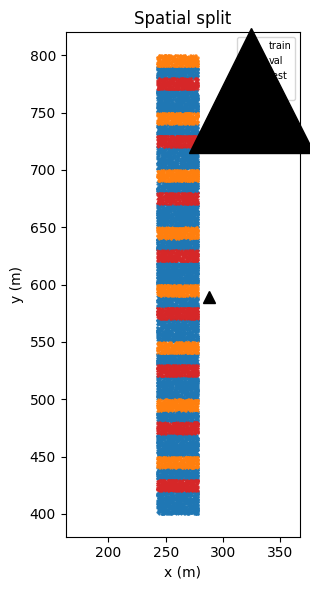

In [ ]:
# A random split puts near-identical neighbours in train and test and inflates
# the results; holding out whole blocks tests real generalisation to new places.
block = np.floor((pos[:, 1] - pos[:, 1].min()) / BLOCK_M).astype(int)
split = np.full(N, 'train', dtype=object)
split[block % 5 == 2] = 'test'
split[block % 5 == 4] = 'val'
idx = {s: np.where(split == s)[0] for s in ['train', 'val', 'test']}
print({s: len(v) for s, v in idx.items()})

plt.figure(figsize=(3.2, 6))
for s, c in [('train', 'tab:blue'), ('val', 'tab:orange'), ('test', 'tab:red')]:
    plt.scatter(pos[idx[s], 0], pos[idx[s], 1], s=0.3, c=c, label=s)
plt.plot(*bs, 'k^', ms=9, label='BS')
plt.xlabel('x (m)'); plt.ylabel('y (m)'); plt.title('Spatial split')
plt.legend(markerscale=1, fontsize=7); plt.axis('equal'); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/split.png', dpi=200); plt.show()

## 4. Preprocessing: complex CSI -> 2 real channels, global normalisation

In [5]:
# Global (not per-sample) scaling keeps the received-power level, which carries
# distance information. Scale and label stats come from the TRAIN set only.
CSI_SCALE = np.sqrt(np.mean(np.abs(H[idx['train']]) ** 2))
POS_MEAN = pos[idx['train']].mean(0); POS_STD = pos[idx['train']].std(0)

def to_input(Hc):
    """complex (n,32,32) -> float tensor (n,2,32,32)"""
    Hn = Hc / CSI_SCALE
    return torch.from_numpy(np.stack([Hn.real, Hn.imag], 1).astype(np.float32))

def to_target(p):  return torch.from_numpy((p - POS_MEAN) / POS_STD)
def from_target(t): return t * POS_STD + POS_MEAN

X = {s: to_input(H[i]) for s, i in idx.items()}
Y = {s: to_target(pos[i]) for s, i in idx.items()}

## 5. Models

In [6]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                                            nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())
        self.f = nn.Sequential(blk(2, 32), nn.MaxPool2d(2),     # 16x16
                               blk(32, 64), nn.MaxPool2d(2),    # 8x8
                               blk(64, 128), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(128, 128), nn.ReLU(), nn.Dropout(0.1), nn.Linear(128, 2))
    def forward(self, x): return self.head(self.f(x))

class ViT(nn.Module):
    """Patches of (pa antennas x ps subcarriers). Positional embedding is
    factorised along the antenna (space/angle) and subcarrier (frequency/delay)
    axes, matching the physical structure of the CSI matrix."""
    def __init__(self, n_ant=32, n_sub=32, pa=4, ps=4, dim=128, depth=4, heads=4, mlp=256, drop=0.1):
        super().__init__()
        self.ga, self.gs = n_ant // pa, n_sub // ps
        self.patch = nn.Conv2d(2, dim, kernel_size=(pa, ps), stride=(pa, ps))
        self.pos_ant = nn.Parameter(torch.zeros(1, dim, self.ga, 1))
        self.pos_sub = nn.Parameter(torch.zeros(1, dim, 1, self.gs))
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        nn.init.trunc_normal_(self.pos_ant, std=.02); nn.init.trunc_normal_(self.pos_sub, std=.02)
        nn.init.trunc_normal_(self.cls, std=.02)
        layer = nn.TransformerEncoderLayer(dim, heads, mlp, drop, activation='gelu',
                                           batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, depth)
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, 2)
    def forward(self, x):
        z = self.patch(x) + self.pos_ant + self.pos_sub        # (B, dim, ga, gs)
        z = z.flatten(2).transpose(1, 2)                       # (B, ga*gs, dim)
        z = torch.cat([self.cls.expand(len(z), -1, -1), z], 1)
        z = self.enc(z)
        return self.head(self.norm(z[:, 0]))

def n_params(m): return sum(p.numel() for p in m.parameters())
print('CNN params:', n_params(CNN()), ' ViT params:', n_params(ViT()))

CNN params: 304386  ViT params: 536834


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17544\324086545.py:27: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.enc = nn.TransformerEncoder(layer, depth)


## 6. Training / evaluation helpers

In [7]:
def predict(model, Xs, bs=1024):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(Xs), bs):
            out.append(model(Xs[i:i + bs].to(device)).cpu())
    return torch.cat(out).numpy()

def errors_m(model, Xs, true_pos):
    return np.linalg.norm(from_target(predict(model, Xs)) - true_pos, axis=1)

def train(model, epochs, lr, name, Xtr=None, Ytr=None):
    Xtr = X['train'] if Xtr is None else Xtr
    Ytr = Y['train'] if Ytr is None else Ytr
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.05)
    steps = epochs * int(np.ceil(len(Xtr) / BATCH))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.1)
    loss_fn = nn.SmoothL1Loss(beta=0.05)
    best, best_state, hist = 1e9, None, []
    t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr)); tot = 0
        for i in range(0, len(Xtr), BATCH):
            b = perm[i:i + BATCH]
            xb, yb = Xtr[b].to(device), Ytr[b].to(device)
            loss = loss_fn(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            tot += loss.item() * len(b)
        val_err = errors_m(model, X['val'], pos[idx['val']]).mean()
        hist.append((tot / len(Xtr), val_err))
        if val_err < best:
            best, best_state = val_err, {k: v.detach().clone() for k, v in model.state_dict().items()}
        if ep % 5 == 0 or ep == epochs - 1:
            print(f'[{name}] ep {ep:3d}  loss {tot/len(Xtr):.4f}  val mean err {val_err:.2f} m')
    model.load_state_dict(best_state)
    print(f'[{name}] done in {time.time()-t0:.0f}s, best val mean err {best:.2f} m')
    return model, np.array(hist)

def summary(e):
    return dict(mean=float(e.mean()), median=float(np.median(e)),
                p90=float(np.percentile(e, 90)), rmse=float(np.sqrt((e ** 2).mean())))

## 7. Train CNN baseline

In [8]:
cnn, hist_cnn = train(CNN(), EPOCHS_CNN, 2e-3, 'CNN')

[CNN] ep   0  loss 0.5148  val mean err 23.18 m
[CNN] ep   5  loss 0.1210  val mean err 24.86 m
[CNN] ep  10  loss 0.0806  val mean err 8.44 m
[CNN] ep  15  loss 0.0684  val mean err 12.42 m
[CNN] ep  20  loss 0.0632  val mean err 9.59 m
[CNN] ep  25  loss 0.0523  val mean err 8.48 m
[CNN] ep  30  loss 0.0485  val mean err 12.15 m
[CNN] ep  35  loss 0.0426  val mean err 9.87 m
[CNN] ep  39  loss 0.0416  val mean err 9.82 m
[CNN] done in 896s, best val mean err 7.81 m


## 8. Train ViT

In [9]:
vit, hist_vit = train(ViT(), EPOCHS_VIT, 1e-3, 'ViT')

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17544\324086545.py:27: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.enc = nn.TransformerEncoder(layer, depth)


[ViT] ep   0  loss 0.6502  val mean err 54.40 m
[ViT] ep   5  loss 0.1076  val mean err 14.09 m
[ViT] ep  10  loss 0.0546  val mean err 5.19 m
[ViT] ep  15  loss 0.0425  val mean err 4.64 m
[ViT] ep  20  loss 0.0322  val mean err 5.19 m
[ViT] ep  25  loss 0.0352  val mean err 4.52 m
[ViT] ep  30  loss 0.0235  val mean err 4.17 m
[ViT] ep  35  loss 0.0192  val mean err 3.93 m
[ViT] ep  40  loss 0.0169  val mean err 3.72 m
[ViT] ep  45  loss 0.0144  val mean err 4.07 m
[ViT] ep  50  loss 0.0124  val mean err 3.82 m
[ViT] ep  55  loss 0.0114  val mean err 3.74 m
[ViT] ep  59  loss 0.0109  val mean err 3.75 m
[ViT] done in 6146s, best val mean err 3.70 m


## 9. Test results: table, CDF, learning curves

CNN: mean 4.81 m | median 2.91 m | 90% 6.04 m | params 304,386 | 104.7 ms / 256 samples
ViT: mean 2.59 m | median 1.78 m | 90% 4.60 m | params 536,834 | 95.7 ms / 256 samples


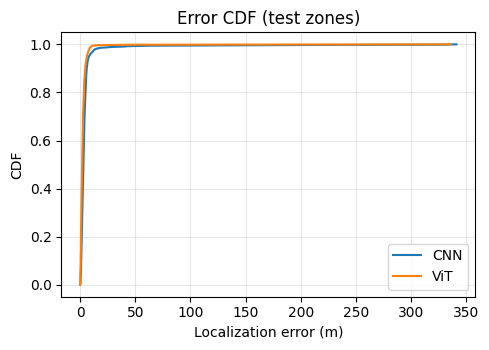

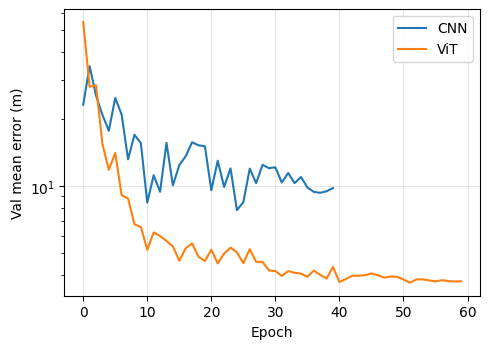

In [10]:
models = {'CNN': cnn, 'ViT': vit}
err = {k: errors_m(m, X['test'], pos[idx['test']]) for k, m in models.items()}
results = {}
for k, m in models.items():
    xb = X['test'][:256].to(device); m.eval()
    with torch.no_grad():
        m(xb); torch.cuda.synchronize() if device == 'cuda' else None
        t0 = time.time(); m(xb); torch.cuda.synchronize() if device == 'cuda' else None
    results[k] = {**summary(err[k]), 'params': n_params(m), 'ms_per_256': 1000 * (time.time() - t0)}
for k, r in results.items():
    print(f"{k}: mean {r['mean']:.2f} m | median {r['median']:.2f} m | 90% {r['p90']:.2f} m | "
          f"params {r['params']:,} | {r['ms_per_256']:.1f} ms / 256 samples")

plt.figure(figsize=(5, 3.6))
for k, e in err.items():
    s = np.sort(e); plt.plot(s, np.arange(1, len(s) + 1) / len(s), label=k)
plt.xlabel('Localization error (m)'); plt.ylabel('CDF'); plt.grid(alpha=.3); plt.legend()
plt.title('Error CDF (test zones)'); plt.tight_layout(); plt.savefig(f'{FIG_DIR}/cdf.png', dpi=200); plt.show()

plt.figure(figsize=(5, 3.6))
plt.plot(hist_cnn[:, 1], label='CNN'); plt.plot(hist_vit[:, 1], label='ViT')
plt.xlabel('Epoch'); plt.ylabel('Val mean error (m)'); plt.yscale('log'); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/learning_curves.png', dpi=200); plt.show()

## 10. Where are the errors? (error map along the street)

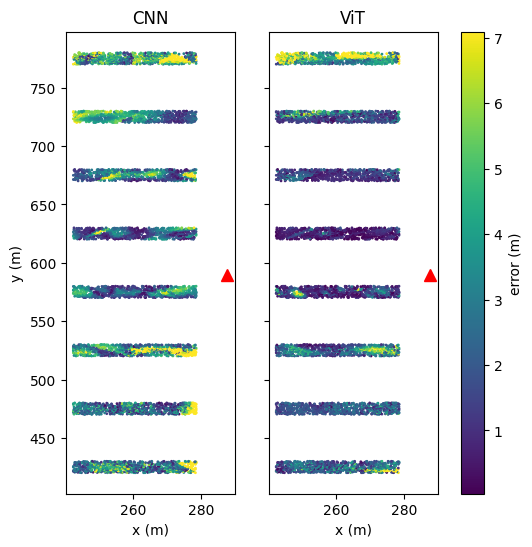

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(6, 6), sharey=True)
vmax = np.percentile(np.concatenate(list(err.values())), 95)
for a, (k, e) in zip(ax, err.items()):
    sc = a.scatter(pos[idx['test'], 0], pos[idx['test'], 1], c=e, s=1, cmap='viridis', vmax=vmax)
    a.plot(*bs, 'r^', ms=9); a.set_title(k); a.set_xlabel('x (m)')
ax[0].set_ylabel('y (m)'); fig.colorbar(sc, ax=ax, label='error (m)')
plt.savefig(f'{FIG_DIR}/error_map.png', dpi=200); plt.show()

## 11. Robustness to noise (test-time AWGN, no retraining)

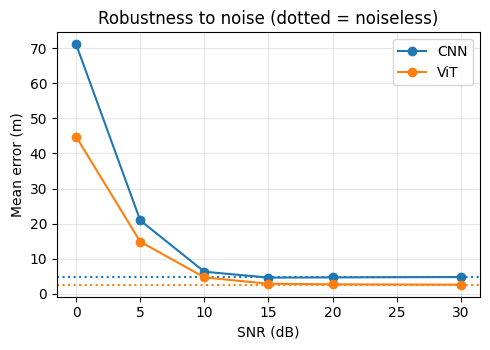

In [12]:
SNRS = [0, 5, 10, 15, 20, 30]
rng = np.random.default_rng(SEED)
Ht = H[idx['test']]
p_sig = np.mean(np.abs(Ht) ** 2, axis=(1, 2), keepdims=True)
snr_res = {k: [] for k in models}
for snr in SNRS:
    noise = (rng.standard_normal(Ht.shape) + 1j * rng.standard_normal(Ht.shape)) / np.sqrt(2)
    Xn = to_input((Ht + np.sqrt(p_sig / 10 ** (snr / 10)) * noise).astype(np.complex64))
    for k, m in models.items():
        snr_res[k].append(errors_m(m, Xn, pos[idx['test']]).mean())
plt.figure(figsize=(5, 3.6))
for k in models:
    plt.plot(SNRS, snr_res[k], 'o-', label=k)
    plt.axhline(results[k]['mean'], ls=':', c=plt.gca().lines[-1].get_color())
plt.xlabel('SNR (dB)'); plt.ylabel('Mean error (m)'); plt.grid(alpha=.3); plt.legend()
plt.title('Robustness to noise (dotted = noiseless)'); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/snr.png', dpi=200); plt.show()

## 12. (Optional) Data size: train on 25 / 50 / 100 % of the training set

[CNN-25%] ep   0  loss 0.7237  val mean err 93.85 m
[CNN-25%] ep   5  loss 0.2199  val mean err 12.07 m
[CNN-25%] ep  10  loss 0.1408  val mean err 19.44 m
[CNN-25%] ep  15  loss 0.1318  val mean err 17.76 m
[CNN-25%] ep  20  loss 0.1195  val mean err 10.98 m
[CNN-25%] ep  25  loss 0.0822  val mean err 7.35 m
[CNN-25%] ep  30  loss 0.0696  val mean err 6.96 m
[CNN-25%] ep  35  loss 0.0695  val mean err 5.33 m
[CNN-25%] ep  39  loss 0.0644  val mean err 5.99 m
[CNN-25%] done in 291s, best val mean err 5.33 m


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17544\324086545.py:27: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.enc = nn.TransformerEncoder(layer, depth)


[ViT-25%] ep   0  loss 0.8205  val mean err 69.63 m
[ViT-25%] ep   5  loss 0.2009  val mean err 21.09 m
[ViT-25%] ep  10  loss 0.1109  val mean err 12.50 m
[ViT-25%] ep  15  loss 0.0868  val mean err 12.79 m
[ViT-25%] ep  20  loss 0.0612  val mean err 7.87 m
[ViT-25%] ep  25  loss 0.0524  val mean err 7.44 m
[ViT-25%] ep  30  loss 0.0545  val mean err 8.23 m
[ViT-25%] ep  35  loss 0.0382  val mean err 7.33 m
[ViT-25%] ep  40  loss 0.0334  val mean err 6.92 m
[ViT-25%] ep  45  loss 0.0301  val mean err 6.41 m
[ViT-25%] ep  50  loss 0.0276  val mean err 6.38 m
[ViT-25%] ep  55  loss 0.0260  val mean err 6.33 m
[ViT-25%] ep  59  loss 0.0264  val mean err 6.32 m
[ViT-25%] done in 1548s, best val mean err 6.29 m
[CNN-50%] ep   0  loss 0.6443  val mean err 48.65 m
[CNN-50%] ep   5  loss 0.1644  val mean err 14.49 m
[CNN-50%] ep  10  loss 0.1430  val mean err 13.13 m
[CNN-50%] ep  15  loss 0.0884  val mean err 11.39 m
[CNN-50%] ep  20  loss 0.0818  val mean err 12.47 m
[CNN-50%] ep  25  loss 

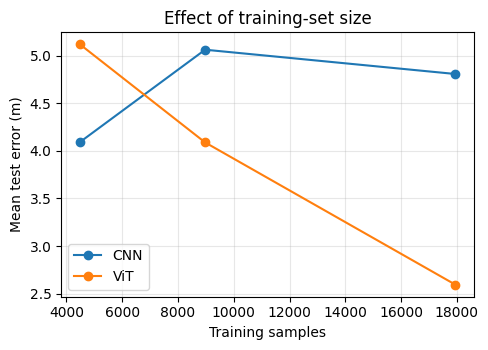

In [13]:
RUN_DATA_SIZE = True
size_res = {}
if RUN_DATA_SIZE:
    fracs = [0.25, 0.5, 1.0]
    size_res = {'CNN': [], 'ViT': []}
    for f in fracs:
        sub = torch.randperm(len(X['train']))[:int(f * len(X['train']))]
        for k, M, ep, lr in [('CNN', CNN, EPOCHS_CNN, 2e-3), ('ViT', ViT, EPOCHS_VIT, 1e-3)]:
            if f == 1.0:
                size_res[k].append(results[k]['mean']); continue
            m, _ = train(M(), ep, lr, f'{k}-{int(f*100)}%', X['train'][sub], Y['train'][sub])
            size_res[k].append(errors_m(m, X['test'], pos[idx['test']]).mean())
    plt.figure(figsize=(5, 3.6))
    for k in size_res:
        plt.plot([int(f * len(X['train'])) for f in fracs], size_res[k], 'o-', label=k)
    plt.xlabel('Training samples'); plt.ylabel('Mean test error (m)'); plt.grid(alpha=.3); plt.legend()
    plt.title('Effect of training-set size'); plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/data_size.png', dpi=200); plt.show()

## 13. Save everything for the article

In [14]:
json.dump({'results': results, 'snr_db': SNRS,
           'snr_mean_err': {k: [float(v) for v in vs] for k, vs in snr_res.items()},
           'data_size_mean_err': {k: [float(v) for v in vs] for k, vs in size_res.items()},
           'split': {s: int(len(v)) for s, v in idx.items()}, 'block_m': BLOCK_M},
          open('results.json', 'w'), indent=2)
torch.save({'cnn': cnn.state_dict(), 'vit': vit.state_dict()}, 'models.pt')
print(json.dumps(results, indent=2))

{
  "CNN": {
    "mean": 4.806448459625244,
    "median": 2.9054737091064453,
    "p90": 6.039303302764893,
    "rmse": 18.840099334716797,
    "params": 304386,
    "ms_per_256": 104.6607494354248
  },
  "ViT": {
    "mean": 2.5936434268951416,
    "median": 1.7821226119995117,
    "p90": 4.604160785675049,
    "rmse": 8.837959289550781,
    "params": 536834,
    "ms_per_256": 95.72362899780273
  }
}


CNN: 42 errors > 50 m (0.69%), 57% of them on the wrong side of the BS, mean |y - y_BS| of those users: 145 m
ViT: 11 errors > 50 m (0.18%), 45% of them on the wrong side of the BS, mean |y - y_BS| of those users: 173 m


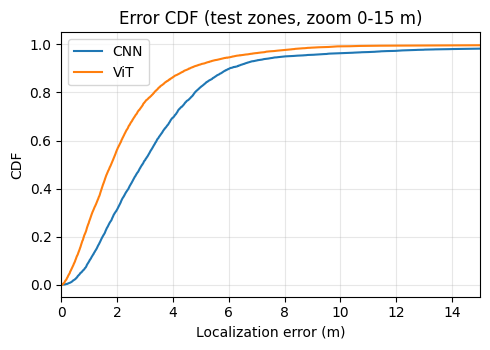

In [15]:
for k, m in models.items():
    pred = from_target(predict(m, X['test']))
    true = pos[idx['test']]
    e = err[k]; bad = e > 50
    mirror = np.sign(pred[bad,1] - bs[1]) != np.sign(true[bad,1] - bs[1])
    print(f"{k}: {bad.sum()} errors > 50 m ({100*bad.mean():.2f}%), "
          f"{mirror.mean()*100:.0f}% of them on the wrong side of the BS, "
          f"mean |y - y_BS| of those users: {np.abs(true[bad,1]-bs[1]).mean():.0f} m")

plt.figure(figsize=(5, 3.6))
for k, e in err.items():
    s = np.sort(e); plt.plot(s, np.arange(1, len(s)+1)/len(s), label=k)
plt.xlim(0, 15); plt.xlabel('Localization error (m)'); plt.ylabel('CDF')
plt.grid(alpha=.3); plt.legend(); plt.title('Error CDF (test zones, zoom 0-15 m)')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/cdf_zoom.png', dpi=200); plt.show()